# Classificação de células sanguíneas com EfficientNetB0
**Equipe:** Felipe Brazão, Felipe Libório, Gabriel Góes e João Ricardo Almeida.  
**Professora:** Polyana Santos Fonseca Nascimento.  
**Disciplina:** Inteligência Computacional / Machine Learning.

## Declaração de uso de IA Generativa
Ferramenta: ChatGPT/Codex (OpenAI). Finalidade: apoio à organização, código Python, notebook, documentação e explicações. Extensão: a versão inicial do código e do texto foi majoritariamente gerada com IA; a equipe deverá atualizar esta declaração para refletir sua contribuição final. Validação prevista: leitura das fontes primárias, revisão do código, execução dos experimentos e conferência das tabelas, imagens e conclusões pela equipe. **Registrar as validações efetivamente realizadas antes da entrega; não declarar como concluídas as verificações ainda pendentes.**

**Estado inicial:** notebook não executado. Não há métricas nem conclusões experimentais inventadas. Complete as análises em Markdown depois de observar as saídas.

## 1. Contexto, objetivo e fontes
O PBC reúne 17.092 imagens JPG de células normais do sangue periférico, com dimensão informada de 360×363 pixels. Oito grupos: basófilos, eosinófilos, eritroblastos, granulócitos imaturos, linfócitos, monócitos, neutrófilos e plaquetas. Os rótulos foram atribuídos por especialistas e a aquisição ocorreu no Hospital Clínic de Barcelona com CellaVision DM96.

Objetivo: classificar o tipo celular de uma imagem. Possível finalidade: apoio à organização e triagem de imagens em pesquisa e ensino. A base não sustenta afirmar detecção de doenças. A distribuição real será calculada a partir dos arquivos.

- [Dataset, versão 1, CC BY 4.0](https://doi.org/10.17632/snkd93bnjr.1)
- [Artigo associado ao dataset](https://doi.org/10.1016/j.cmpb.2019.105020)
- [Tan e Le — EfficientNet, ICML 2019](https://arxiv.org/abs/1905.11946)
- [Documentação oficial Torchvision](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html)
- [Selvaraju et al. — Grad-CAM, ICCV 2017](https://arxiv.org/abs/1610.02391)

O dataset e a arquitetura EfficientNetB0 foram validados pela professora na planilha de equipes.

## 2. Arquitetura pesquisada
Mingxing Tan e Quoc V. Le publicaram EfficientNet em 2019. A inovação central é o **escalonamento composto**: aumentar profundidade, largura e resolução de forma coordenada, em vez de ajustar somente uma dimensão. A B0 é a arquitetura base da família, definida com busca de arquitetura; as variantes maiores derivam de seu escalonamento. Escolhemos a versão reservada pela equipe e adequada a recursos computacionais moderados.

MBConv é um bloco de gargalo invertido: expansão 1×1 (quando a razão é maior que 1), convolução depthwise, squeeze-and-excitation e projeção 1×1. Atalhos residuais conectam blocos compatíveis em dimensão e stride. Squeeze-and-excitation recalibra canais; SiLU é a ativação. Ao final, pooling global agrega informação espacial e dropout regulariza o classificador.

| Estágio | Operação | Resolução de saída | Canais | Repetições |
|---|---|---|---:|---:|
| Stem | Conv 3×3 | 112×112 | 32 | 1 |
| 1 | MBConv1, k3 | 112×112 | 16 | 1 |
| 2 | MBConv6, k3 | 56×56 | 24 | 2 |
| 3 | MBConv6, k5 | 28×28 | 40 | 2 |
| 4 | MBConv6, k3 | 14×14 | 80 | 3 |
| 5 | MBConv6, k5 | 14×14 | 112 | 3 |
| 6 | MBConv6, k5 | 7×7 | 192 | 4 |
| 7 | MBConv6, k3 | 7×7 | 320 | 1 |
| Final | Conv 1×1 + pooling + dropout + linear | 1×1 | 1280 → 8 | 1 |

Na implementação Torchvision, `features[0]` é o stem, `[1]` a `[7]` são os estágios MBConv e `[8]` é a convolução final. O classificador original de 1.000 classes é substituído por uma camada linear de oito saídas. O código imprime a rede adaptada e seus parâmetros reais.

In [1]:
from pathlib import Path
import sys

# Funciona abrindo na raiz do projeto ou em notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'pipeline.py').exists() and (ROOT.parent / 'src' / 'pipeline.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'pipeline.py').exists():
    raise FileNotFoundError('Ajuste ROOT para a pasta Trabalho-CNN com src/pipeline.py.')
sys.path.insert(0, str(ROOT))
from src import pipeline as p
from IPython.display import display
ROOT, DEVICE = p.setup(ROOT)


{'torch': '2.15.0', 'torchvision': '0.29.2', 'numpy': '2.5.5', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'Pillow': '12.3.0', 'matplotlib': '3.11.2', 'python': '3.12.2', 'device': 'cpu', 'seed': 42}


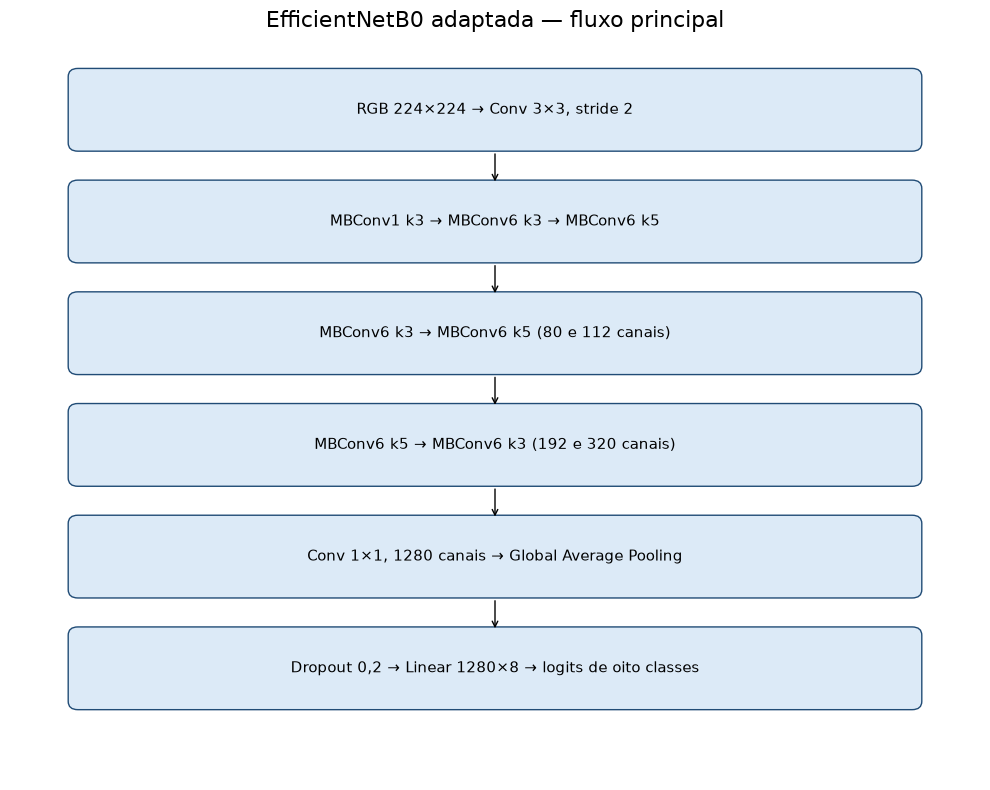

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Diagrama esquemático próprio, baseado na tabela da arquitetura B0 do artigo.
fig, ax = plt.subplots(figsize=(10, 8))
ax.set(xlim=(0, 10), ylim=(0, 9))
ax.axis('off')
stages = ['RGB 224×224 → Conv 3×3, stride 2',
          'MBConv1 k3 → MBConv6 k3 → MBConv6 k5',
          'MBConv6 k3 → MBConv6 k5 (80 e 112 canais)',
          'MBConv6 k5 → MBConv6 k3 (192 e 320 canais)',
          'Conv 1×1, 1280 canais → Global Average Pooling',
          'Dropout 0,2 → Linear 1280×8 → logits de oito classes']
for i, label in enumerate(stages):
    y = 7.7 - i * 1.35
    ax.add_patch(FancyBboxPatch((.7, y), 8.6, .8, boxstyle='round,pad=0.1',
                              facecolor='#dceaf7', edgecolor='#214c76'))
    ax.text(5, y+.4, label, ha='center', va='center', fontsize=11)
    if i < len(stages)-1:
        ax.annotate('', xy=(5, y-.5), xytext=(5, y-.1), arrowprops={'arrowstyle':'->'})
ax.set_title('EfficientNetB0 adaptada — fluxo principal', fontsize=16)
fig.tight_layout()
fig.savefig(ROOT / 'results/figures/architecture.png', dpi=180)
plt.show()


## 3. Dados, integridade e holdout
Baixe e extraia a versão 1 do PBC em `data/raw`, preservando as pastas das classes (ver README). O inventário verifica leitura das imagens, dimensões e canais. Remove duplicatas de pixels idênticos antes da divisão e exclui integralmente os grupos com rótulos conflitantes, registrando os casos. Arquivos inválidos são registrados e excluídos.

Divisão estratificada 70% treino, 15% validação, 15% teste com seed 42. Os manifestos são persistidos e só são reutilizados se o inventário tiver a mesma identidade. A exploração visual e de dimensões detalhadas usa apenas treino. Do teste, mostramos somente a quantidade por classe para auditar a estratificação; não usamos imagens, previsões ou métricas no ajuste.

**Limitação:** não assumimos IDs de pacientes. Verifique a documentação: se houver identificadores confiáveis, a separação deve ser por paciente para evitar dependências entre as divisões. Remover duplicatas exatas não elimina amostras semelhantes.

Inventário: 1000 arquivos examinados...
Inventário: 2000 arquivos examinados...
Inventário: 3000 arquivos examinados...
Inventário: 4000 arquivos examinados...
Inventário: 5000 arquivos examinados...
Inventário: 6000 arquivos examinados...
Inventário: 7000 arquivos examinados...
Inventário: 8000 arquivos examinados...
Inventário: 9000 arquivos examinados...
Inventário: 10000 arquivos examinados...
Inventário: 11000 arquivos examinados...
Inventário: 12000 arquivos examinados...
Inventário: 13000 arquivos examinados...
Inventário: 14000 arquivos examinados...
Inventário: 15000 arquivos examinados...
Inventário: 16000 arquivos examinados...
Inventário: 17000 arquivos examinados...
Imagens válidas únicas: 17074; duplicatas removidas: 16; arquivos com rótulos conflitantes excluídos: 2; inválidas: 1
              train  val  test
label                         
basophil        848  182   182
eosinophil     2177  466   467
erythroblast   1086  233   232
ig             2024  434   434
lymphocy

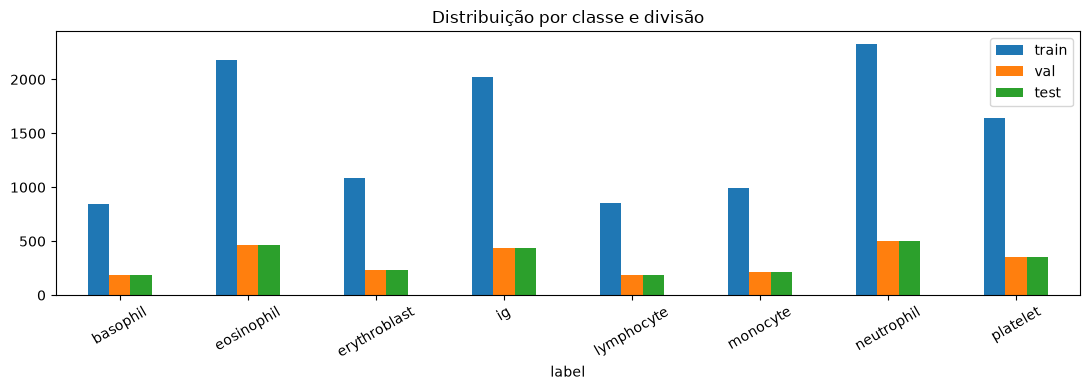

Dimensões do treino:
 width  height
359    360           1
360    360         147
       361           1
       363       11627
361    360           1
362    360           1
366    369         173
dtype: int64
Canais originais no treino:
 mode
RGB    11951
Name: count, dtype: int64


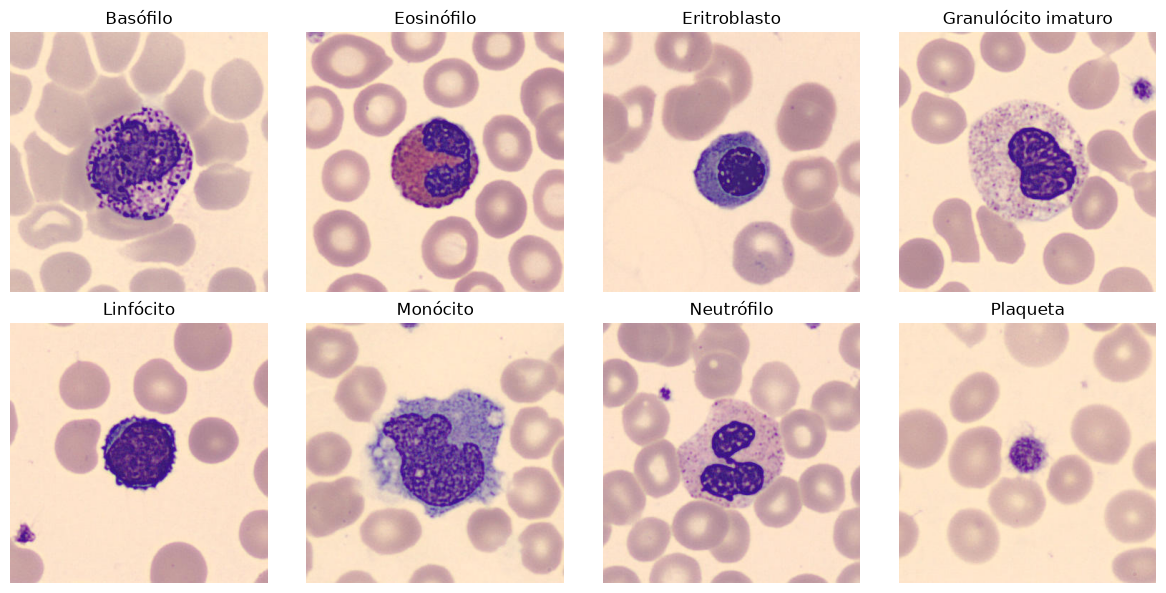

,path,label,target,width,height,mode,sha256
0,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,basophil,0,360,363,RGB,ebbb1ac79a03160eb3ff0eb7db6c1610b3aa99fee25685...
1,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,basophil,0,360,363,RGB,73bb2155b4da9cc136ee1c7a2464cdb8c6341823c05ea4...
2,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,basophil,0,360,363,RGB,28bbed2090564e3457f2578625e35cfaf9308d3cbe8e2e...
3,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,basophil,0,360,363,RGB,284916c7b981ec712ae4838a86278016fb675ce0c1371d...
4,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,basophil,0,360,363,RGB,f51f647d532210140f9c818033bed1a6d4afd1017cd66c...


In [3]:
inventory = p.inventory(ROOT)
parts = p.split_data(ROOT, inventory)
p.analysis(ROOT, parts)
display(inventory.head())


### Análise inicial — resultados da auditoria local
Foram decodificadas 17.092 imagens. Um arquivo JPG adicional era ilegível; 20 recursos macOS não são imagens utilizáveis. Identificamos uma imagem com rótulos conflitantes em `eosinophil/EO_225902.jpg` e `neutrophil/BNE_191112.jpg`: excluímos ambos os arquivos do experimento. Removemos mais 16 cópias exatas, restando **17.074 imagens únicas**.

Holdout: **11.951 treino, 2.561 validação e 2.562 teste**, sem hashes compartilhados. Os manifestos preservam a divisão estratificada e a semente 42. Os arquivos originais permanecem intactos.

No treino, todas as imagens são RGB. A maioria mede 360×363 (11.627); há também 366×369 (173), 360×360 (147) e quatro casos em outros tamanhos. Assim, redimensionar explicitamente é necessário. As classes vão de 1.212 basófilos a 3.328 neutrófilos na base limpa, uma razão de aproximadamente 2,75. Macro F1 evita que as maiores classes dominem a comparação.

As amostras mostram diferenças de tamanho relativo, granulação e proporção núcleo/citoplasma, além de hemácias e fundo. Essas observações motivam a análise posterior de Grad-CAM. Não foram inspecionadas imagens do teste para formular essas observações. O detalhamento por classe e os critérios estão em `docs/auditoria_dataset.md`.

![Distribuição auditada](results/figures/distribution.png)
![Amostras somente de treino](results/figures/train_samples.png)


## 4. Pré-processamento, métricas e critérios
RGB; resize bicúbico direto para 224×224, tensor [0,1], normalização com média `[0.485,0.456,0.406]` e desvio `[0.229,0.224,0.225]` do ImageNet. Preservamos toda a célula, com pequena alteração de proporção para imagens 360×363. Essa decisão difere do crop central do preset oficial e deve ser discutida. Validação, teste e inferência usam exatamente a mesma transformação determinística. No treino, flips horizontal/vertical e rotação ±20° simulam orientações sem alterar o rótulo; não introduzimos variações arbitrárias de cor.

Métrica principal: **macro F1**, com pesos iguais por classe. Complementares: acurácia, balanced accuracy (média de recall), F1 ponderado, precisão/recall/F1 por classe e matriz de confusão. Uma confusão entre granulócitos imaturos e neutrófilos pode comprometer a caracterização de maturação celular; sua relevância deve ser discutida sem alegar diagnóstico. As confusões observadas e os recalls por classe orientam essa análise.

Mesmo batch 32, AdamW, weight decay 1e-4 e paciência 4. A base congelada completou 15 épocas; a A usa as 12 épocas completas e a B terá máximo de 12 épocas, definido antes da sua execução. Sem busca com Optuna. O melhor checkpoint é o de maior macro F1 na validação. A recomendação segue o mesmo critério; em empate exato, menor tempo e depois menos parâmetros treináveis. Uma única semente não permite alegar significância estatística.

**BatchNorm:** estatísticas fixas em todas as condições; nos blocos descongelados, os parâmetros afins continuam ajustáveis. Taxas e blocos foram definidos antes de consultar teste.

In [4]:
model = p.build()
p.configure(model, 'frozen')
print(model)
print('Entrada:', (32, 3, 224, 224), '| Saída:', (32, 8))
print('Total:', sum(x.numel() for x in model.parameters()))
print('Treináveis:', sum(x.numel() for x in model.parameters() if x.requires_grad))
display(p.pd.DataFrame([{'índice': i, 'classe': cls, 'nome': pt}
                       for i, (cls, pt) in enumerate(zip(p.CLASSES, p.LABELS_PT))]))
del model


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

,índice,classe,nome
0,0,basophil,Basófilo
1,1,eosinophil,Eosinófilo
2,2,erythroblast,Eritroblasto
3,3,ig,Granulócito imaturo
4,4,lymphocyte,Linfócito
5,5,monocyte,Monócito
6,6,neutrophil,Neutrófilo
7,7,platelet,Plaqueta


## 5. Transfer learning: base congelada
Pesos `IMAGENET1K_V1` da implementação oficial Torchvision. Somente o novo classificador é treinado. Salvamos o melhor checkpoint em `models/frozen.pt`. As estratégias seguintes carregarão cópias independentes deste mesmo estado.

In [5]:
frozen_config = p.train(ROOT, parts, DEVICE, 'frozen', epochs=15, batch_size=32)
display(frozen_config)


frozen | época 1/15 | lote 1/374 | loss do lote 2.1788 | decorrido 1s
frozen | época 1/15 | lote 50/374 | loss do lote 1.2181 | decorrido 41s
frozen | época 1/15 | lote 100/374 | loss do lote 1.0059 | decorrido 82s
frozen | época 1/15 | lote 150/374 | loss do lote 1.0145 | decorrido 122s
frozen | época 1/15 | lote 200/374 | loss do lote 0.9662 | decorrido 162s
frozen | época 1/15 | lote 250/374 | loss do lote 0.6945 | decorrido 202s
frozen | época 1/15 | lote 300/374 | loss do lote 0.6201 | decorrido 245s
frozen | época 1/15 | lote 350/374 | loss do lote 0.8263 | decorrido 287s
frozen {'epoch': 1, 'train_loss': 0.9113, 'train_macro_f1': 0.6812, 'val_loss': 0.6168, 'val_macro_f1': 0.7984}
frozen | época 2/15 | lote 1/374 | loss do lote 0.3808 | decorrido 376s
frozen | época 2/15 | lote 50/374 | loss do lote 0.5933 | decorrido 417s
frozen | época 2/15 | lote 100/374 | loss do lote 0.4018 | decorrido 460s
frozen | época 2/15 | lote 150/374 | loss do lote 0.4935 | decorrido 501s
frozen | é

{'strategy': 'frozen',
 'trainable': 10248,
 'total': 4017796,
 'epochs': 15,
 'seconds': 5500.613552800001,
 'learning_rate': 0.001,
 'batch_size': 32,
 'optimizer': 'AdamW',
 'weight_decay': 0.0001,
 'patience': 4,
 'selection': 'validation macro F1',
 'max_epochs': 15}

### Resultado preliminar para o acompanhamento
Execute a célula abaixo para apresentar curvas e exemplos da base congelada antes dos fine-tunings. Ela usa somente validação.

{'loss': 0.30391474418619946,
 'accuracy': 0.9016009371339321,
 'balanced_accuracy': 0.8926648125544439,
 'macro_f1': 0.8930684045094812,
 'weighted_f1': 0.9006220825889413}

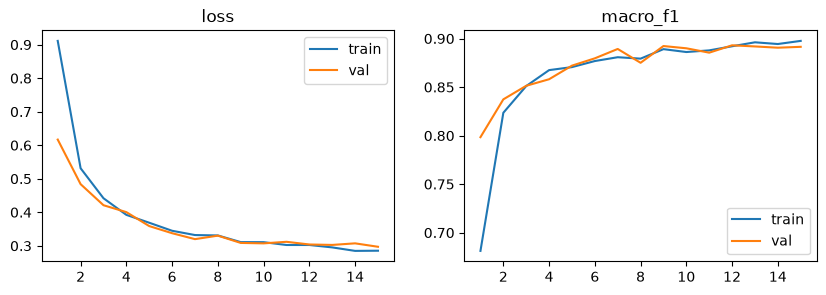

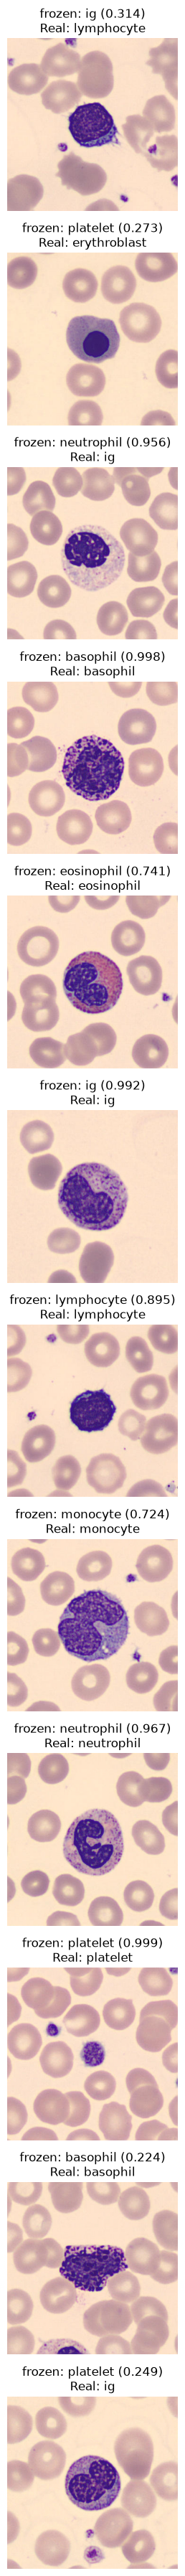

,path,real,frozen
0,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,lymphocyte,ig
1,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,erythroblast,platelet
2,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,ig,neutrophil
3,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,basophil,basophil
4,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,eosinophil,eosinophil
5,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,ig,ig
6,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,lymphocyte,lymphocyte
7,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,monocyte,monocyte
8,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,neutrophil,neutrophil
9,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,platelet,platelet


In [6]:
frozen = p.load_checkpoint(ROOT, 'frozen', DEVICE)
frozen_metrics, y_val, frozen_prob = p.evaluate(frozen, p.loader(ROOT, parts['val']), DEVICE)
display(frozen_metrics)
h = p.pd.read_csv(ROOT / 'results/metrics/history_frozen.csv')
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ['loss', 'macro_f1']):
    for subset in ['train', 'val']:
        ax.plot(h.epoch, h[f'{subset}_{metric}'], label=subset)
    ax.set_title(metric)
    ax.legend()
plt.show()
preliminary = parts['val'][['path', 'label', 'target']].reset_index(drop=True).copy()
preliminary['prediction'] = frozen_prob.argmax(1)
preliminary['score'] = frozen_prob.max(1)
display(p.visual_errors(ROOT, {'frozen': preliminary}))
del frozen


### Análise da base congelada
O checkpoint selecionado pelo macro F1 de validação é o da época 12: macro F1 89,31%, acurácia 90,16% e loss 0,3039. As 15 épocas foram realizadas, mas a última não é o checkpoint escolhido (macro F1 89,15%). A loss final é um pouco menor, o que ilustra que melhorar cross-entropy não implica melhorar o F1 da decisão argmax.

As curvas de treino e validação evoluem juntas e se estabilizam, sem divergência forte. O desempenho inferior ao fine-tuning sugere que as características fixas de ImageNet limitam a tarefa; as curvas isoladamente não provam a causa. Os menores recalls são os de monócitos (76,06%) e granulócitos imaturos (81,80%). Augmentation e dropout no treino ajudam a explicar diferenças entre as curvas de treino e validação.

## 6. Duas estratégias de fine-tuning
**A:** descongelar `features[6:]` e classificador, LR 1e-4. Ajuste mais localizado nas representações finais.  
**B:** descongelar `features[4:]` e classificador, LR 1e-5. Permite adaptar mais estágios com passos menores.

Ambas partem de `frozen.pt`, reiniciam o otimizador e usam as mesmas divisões, seed, transformações, batch e regras de seleção. Não inicializamos B com A. Como variamos blocos e LR juntos, comparamos estratégias completas; não isolamos o efeito de cada fator.

### Configuração consolidada
A condição A é avaliada com as 12 épocas completas e o checkpoint da melhor validação, sem reiniciar o treinamento. A B foi configurada, antes da execução, com máximo de 12 épocas e paciência 4; permanece pendente. A base congelada conserva as 15 épocas realizadas. As duas estratégias continuam partindo do mesmo checkpoint congelado.

O tempo da A é estimado a partir do primeiro registro da época seguinte e será identificado como aproximação na tabela. A execução original e seu histórico foram preservados para rastreabilidade em `results/metrics/original_ft_a_execution.json`. Essa limitação impede tratar pequenas diferenças de tempo como conclusivas.


In [ ]:
# Reutiliza as 12 épocas completas já consolidadas; não treina novamente.
from importlib import reload
p = reload(p)
a_config_path = ROOT / 'results/metrics/config_ft_a.json'
if a_config_path.exists() and (ROOT / 'models/ft_a.pt').exists():
    ft_a_config = p.json.loads(a_config_path.read_text(encoding='utf-8'))
    print('A: reutilizando o checkpoint e as 12 épocas completas salvas.')
else:
    # Em um ambiente novo, reproduz a condição com máximo de 12 épocas.
    ft_a_config = p.train(ROOT, parts, DEVICE, 'ft_a', epochs=12, batch_size=32)
display(ft_a_config)


In [1]:
# Esta célula pode ser executada diretamente após reiniciar o PC.
from pathlib import Path
import sys
from importlib import reload
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src/pipeline.py').is_file() and (ROOT.parent / 'src/pipeline.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'src/pipeline.py').is_file():
    raise FileNotFoundError('Abra o notebook na pasta Trabalho-CNN.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import pipeline as p
p = reload(p)
ROOT, DEVICE, parts = p.prepare_b_context(ROOT)

b_config_path = ROOT / 'results/metrics/config_ft_b.json'
if b_config_path.exists() and (ROOT / 'models/ft_b.pt').exists():
    ft_b_config = p.json.loads(b_config_path.read_text(encoding='utf-8'))
    print('B já concluída: reutilizando os resultados salvos.')
else:
    ft_b_config = p.train(ROOT, parts, DEVICE, 'ft_b', epochs=12, batch_size=32)
display(ft_b_config)


{'torch': '2.15.0', 'torchvision': '0.29.2', 'numpy': '2.5.5', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'Pillow': '12.3.0', 'matplotlib': '3.11.2', 'python': '3.12.2', 'device': 'cpu', 'seed': 42}
frozen: 15 épocas preservadas; sem novo treinamento.
ft_a: 12 épocas preservadas; sem novo treinamento.
Imagens válidas únicas: 17074; duplicatas removidas: 16; arquivos com rótulos conflitantes excluídos: 2; inválidas: 1
              train  val  test
label                         
basophil        848  182   182
eosinophil     2177  466   467
erythroblast   1086  233   232
ig             2024  434   434
lymphocyte      850  182   182
monocyte        993  213   213
neutrophil     2329  499   500
platelet       1644  352   352
Contexto restaurado. B partirá de frozen.pt; teste permanece reservado.
ft_b | época 1/12 | lote 1/374 | loss do lote 0.4514 | decorrido 5s
ft_b | época 1/12 | lote 50/374 | loss do lote 0.3870 | decorrido 94s
ft_b | época 1/12 | lote 100/374 | loss do lote 0.3190 | d

{'strategy': 'ft_b',
 'trainable': 3952066,
 'total': 4017796,
 'epochs': 12,
 'seconds': 7991.018977800006,
 'learning_rate': 1e-05,
 'batch_size': 32,
 'optimizer': 'AdamW',
 'weight_decay': 0.0001,
 'patience': 4,
 'selection': 'validation macro F1',
 'max_epochs': 12}

## 7. Comparação pela validação
As tabelas incluem métricas, parâmetros treináveis, épocas efetivas e tempo. Os relatórios por classe e previsões individuais são exportados. Tempo de treinamento inclui validações e salvamento de checkpoints, mas exclui carga inicial de pesos; compare nas mesmas condições de hardware.

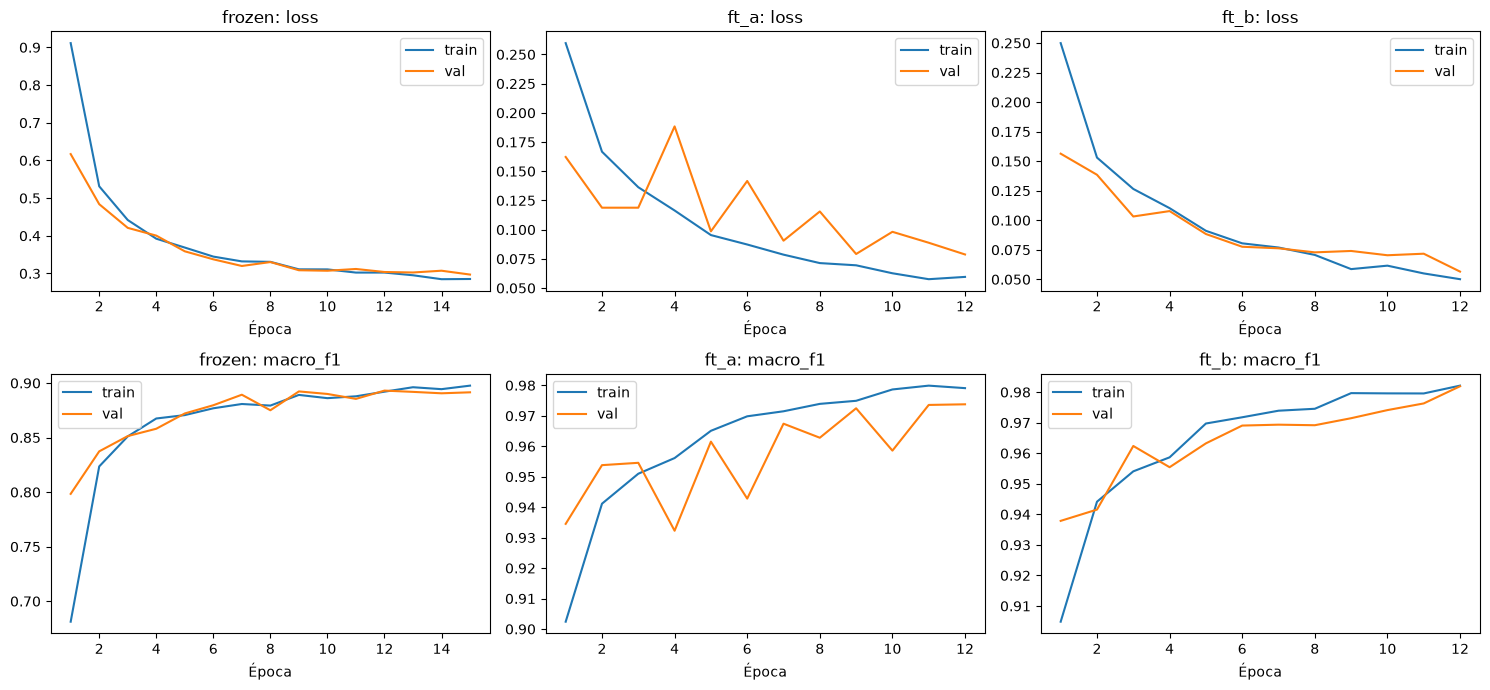

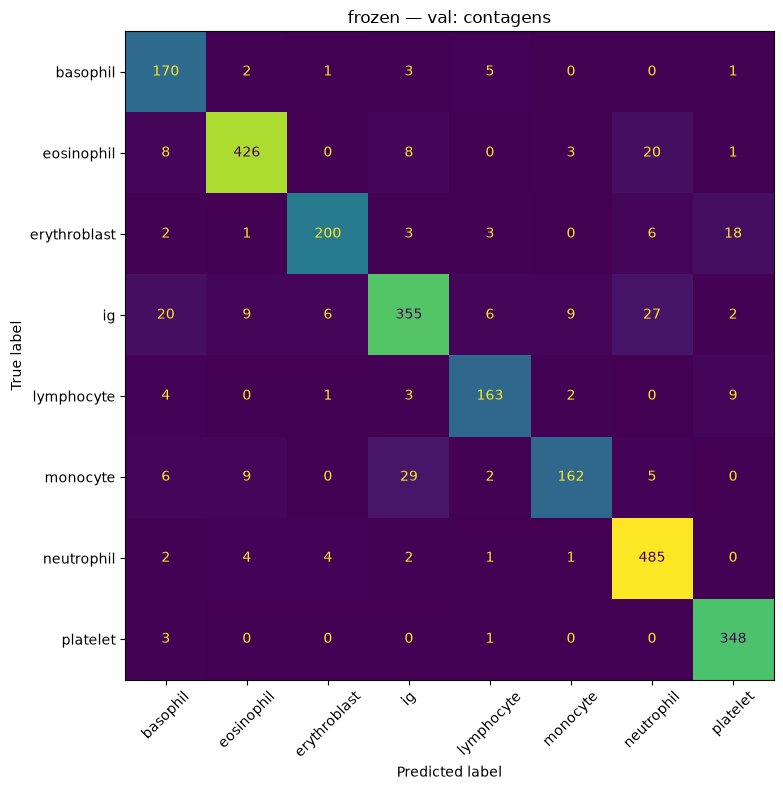

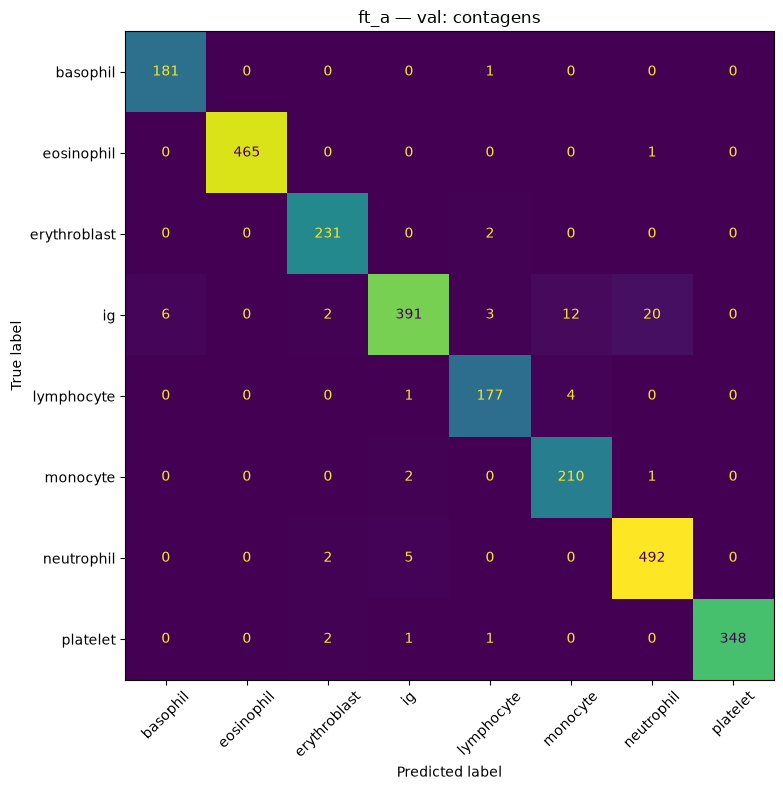

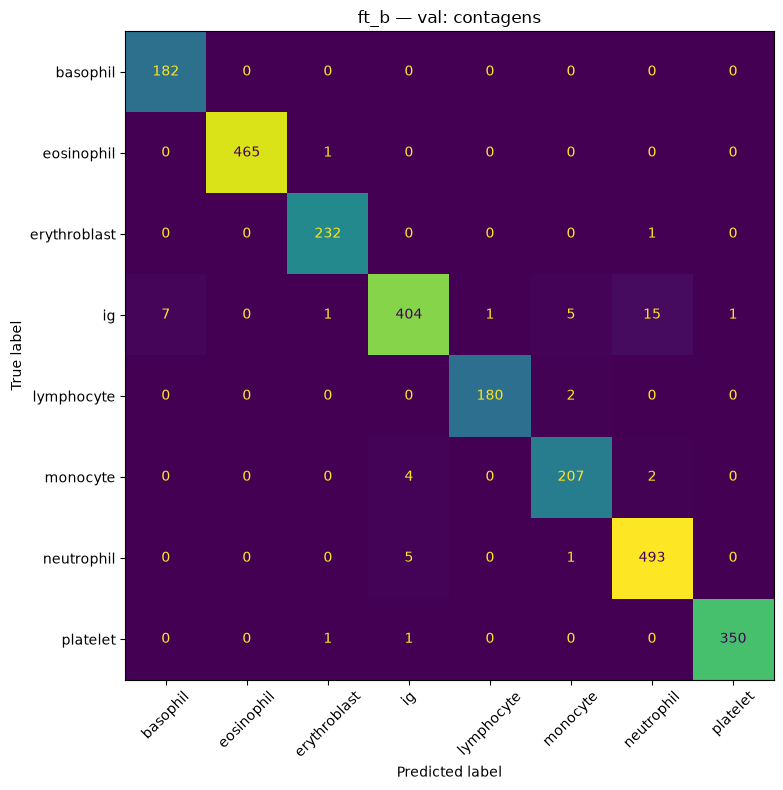

,model,loss,accuracy,balanced_accuracy,macro_f1,weighted_f1,trainable,epochs,seconds,time_measurement,time_note
0,frozen,0.303915,0.901601,0.892665,0.893068,0.900622,10248,15,5500.613553,measured,Tempo medido durante a execução.
1,ft_a,0.078755,0.974229,0.977219,0.973772,0.974049,3165988,12,5365.000000,estimate,Estimativa baseada no tempo acumulado impresso...
2,ft_b,0.056573,0.981257,0.983447,0.981917,0.981168,3952066,12,7991.018978,measured,Tempo medido durante a execução.


In [2]:
if not (ROOT / 'results/metrics/config_ft_b.json').exists():
    raise RuntimeError('A B ainda não foi concluída. Comparação e teste permanecem pendentes.')
p.curves(ROOT)
validation_table, validation_predictions = p.compare(ROOT, parts, DEVICE, 'val')
display(validation_table)


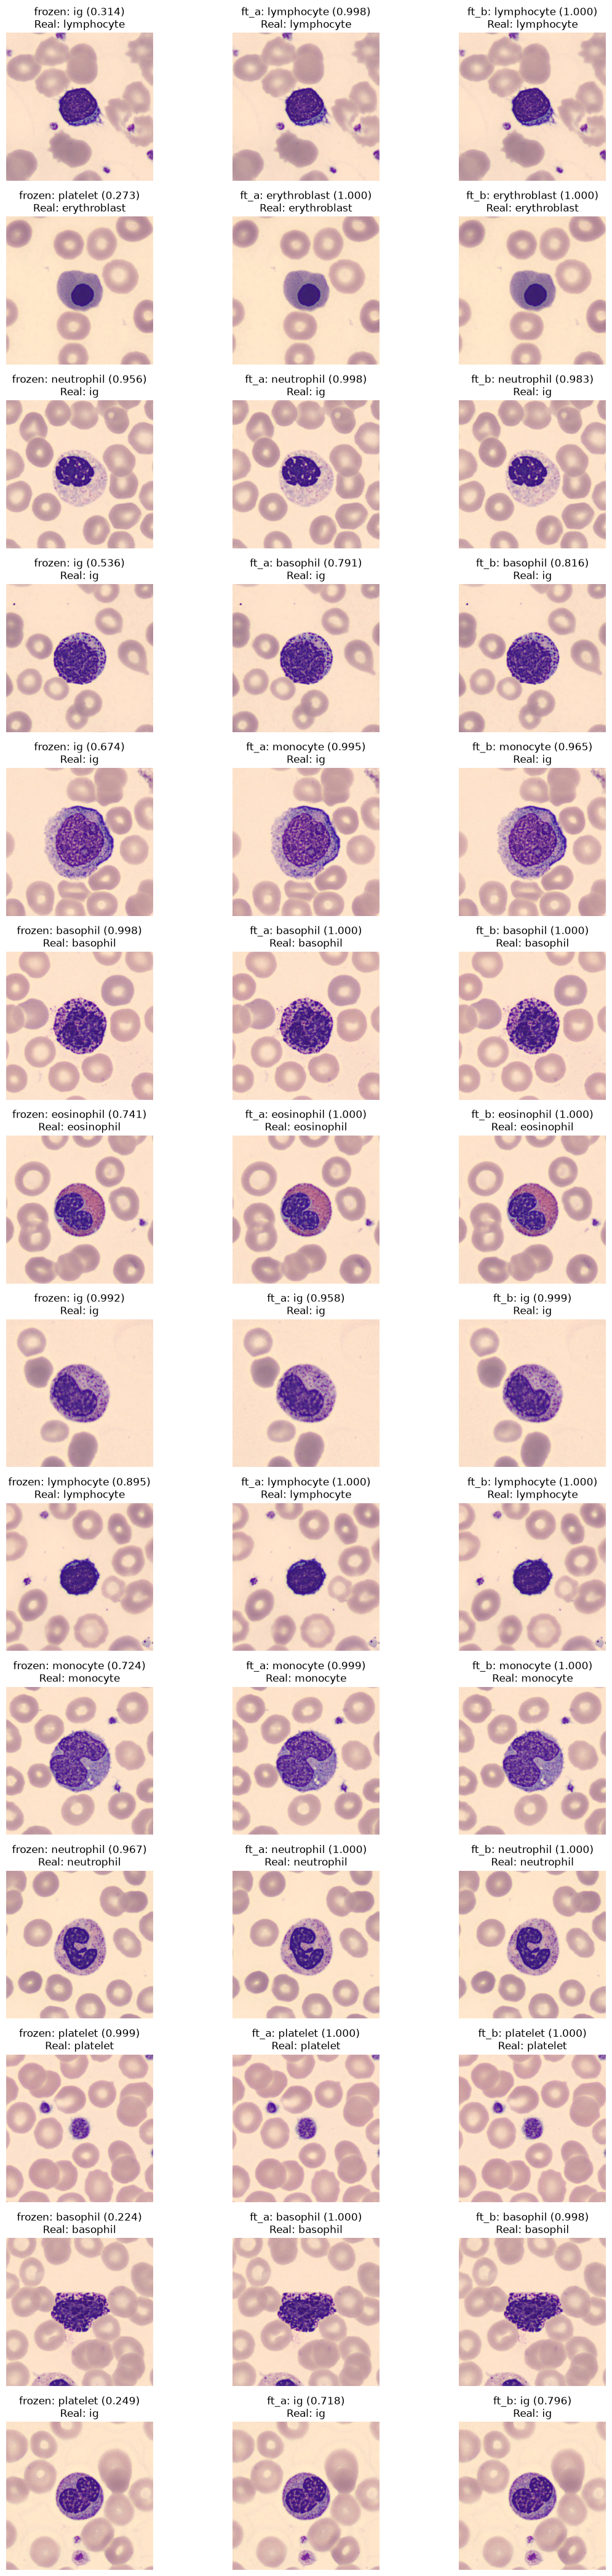

,path,real,frozen,ft_a,ft_b
0,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,lymphocyte,ig,lymphocyte,lymphocyte
1,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,erythroblast,platelet,erythroblast,erythroblast
2,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,ig,neutrophil,neutrophil,neutrophil
3,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,ig,ig,basophil,basophil
4,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,ig,ig,monocyte,monocyte
5,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,basophil,basophil,basophil,basophil
6,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,eosinophil,eosinophil,eosinophil,eosinophil
7,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,ig,ig,ig,ig
8,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,lymphocyte,lymphocyte,lymphocyte,lymphocyte
9,data/raw/PBC_dataset_normal_DIB/PBC_dataset_no...,monocyte,monocyte,monocyte,monocyte


In [3]:
visual_cases = p.visual_errors(ROOT, validation_predictions)
display(visual_cases)


### Comparação crítica pela validação
| Condição | Macro F1 | Acurácia | Balanced accuracy | Épocas | Tempo da etapa |
|---|---:|---:|---:|---:|---:|
| Base congelada | 89,31% | 90,16% | 89,27% | 15 | 91,7 min, medido |
| Fine-tuning A | 97,38% | 97,42% | 97,72% | 12 completas | aproximadamente 89,4 min |
| Fine-tuning B | 98,19% | 98,13% | 98,34% | 12 | 133,2 min, medido |

Os dois fine-tunings partem do mesmo checkpoint congelado. Os tempos de A/B representam as etapas adicionais; a etapa inicial de 91,7 min é comum. O tempo da A inclui o primeiro lote da época 13 e é uma estimativa, não uma medição exata das 12 épocas.

B ganha 0,81 ponto percentual de macro F1 sobre A. O recall de granulócitos imaturos passa de 90,09% para 93,09%, mas o de monócitos recua de 98,59% para 97,18%. Granulócitos imaturos continuam sendo a classe com menor F1 da B (95,28%). O F1 por classe da B melhora ou empata com A, mas isso não implica melhora em precisão e recall separadamente em todas as classes.

Nas mesmas imagens, LY_468617 (linfócito) e ERB_772930 (eritroblasto) são corrigidos por A e B. MY_562076 permanece confundido com neutrófilo nos três modelos. PMY_374709 e PMY_191869, granulócitos imaturos corretamente classificados pela base, passam a basófilo e monócito nos dois fine-tunings. O ganho agregado coexiste com novos erros. As imagens e matrizes orientam hipóteses sobre semelhanças morfológicas; não houve revisão de rótulos por especialista.

As curvas de B são relativamente suaves, com F1 de treino e validação próximos ao final. A loss de validação da A oscila mais, embora o melhor checkpoint ainda melhore na época 12. A comparação é descritiva de uma única semente/divisão, não um teste de significância. Nenhuma conclusão de teste é apresentada nesta etapa.

## 8. Explicabilidade: Grad-CAM
Camada `features[-1]`, saída da convolução final de 1280 canais. Em cada caso usamos o logit da **classe real**, mantendo a classe investigada fixa nos três modelos para comparação. A classe prevista aparece no título. A entrada requer gradiente, o que permite obter mapas mesmo com a base congelada.

Média espacial dos gradientes → pesos por canal → soma ponderada dos mapas → ReLU → interpolação. A normalização de cada mapa é individual; cores não representam magnitude absoluta comparável entre redes. Grad-CAM é grosseiro (mapa original 7×7), não segmenta a célula nem prova causalidade.

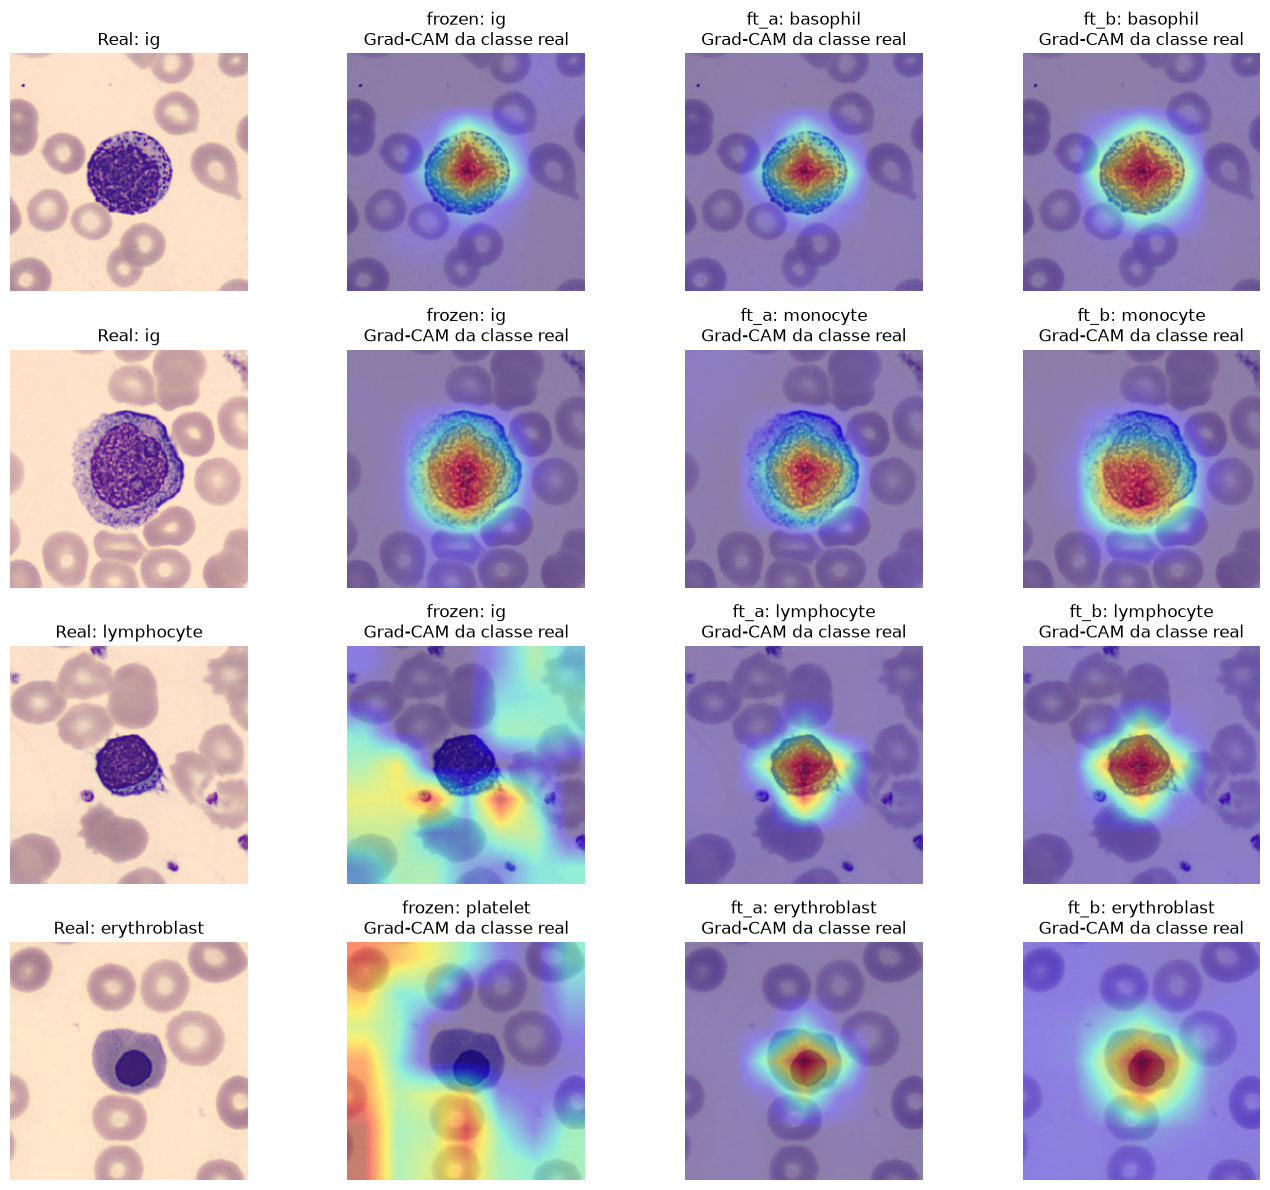

In [4]:
p.explain(ROOT, validation_predictions, DEVICE)


### Interpretação dos mapas
Os mapas comparam a **classe real** nas mesmas quatro imagens, na camada `features[-1]`, com normalização individual.

Em LY_468617 e ERB_772930, A e B corrigem a previsão e concentram os destaques na célula de interesse; a base destaca também hemácias, regiões periféricas e fundo. Essa mudança é compatível com uma localização mais pertinente, mas não comprova um mecanismo biológico.

Em PMY_374709 e PMY_191869, todas as condições destacam a célula central, porém A/B erram o rótulo. Localizar a célula não basta para distinguir classes semelhantes. Como os mapas investigam a classe real, eles não são explicações diretas da classe errada prevista. Para estudar essa classe seria necessário outro mapa com alvo diferente.

Não há base para afirmar que B é superior a A somente pela aparência desses mapas. As cores são normalizadas por imagem/modelo, não comparam magnitude absoluta; a resolução original 7×7 é grosseira. As interpretações são hipóteses qualitativas, sem provar causalidade.

## 9. Recomendação registrada ANTES do teste
Use a validação e as análises anteriores. A função aplica a regra previamente definida e salva a justificativa e o modelo recomendado. **Preencha a variável abaixo antes de continuar.** Não altere a recomendação depois de abrir o teste. Não escreva que um resultado aconteceu sem observá-lo.

In [7]:
JUSTIFICATIVA = """Recomendamos o fine-tuning B conforme a regra definida de maior macro F1 na validação: 0,981917 (98,19%), contra 0,973772 (97,38%) em A e 0,893068 (89,31%) na base congelada. O ganho é de 0,81 ponto percentual sobre A e 8,88 pontos sobre a referência. B também apresenta maior balanced accuracy (98,34%) e menor loss de validação (0,05657). A seleção usa exclusivamente as 2.561 imagens de validação; o teste não foi consultado.

O F1 de granulócitos imaturos melhora de 93,76% em A para 95,28% em B, e o de linfócitos de 96,72% para 99,17%. Em contrapartida, o recall de monócitos cai de 98,59% para 97,18%; portanto, B não domina A em todas as métricas de todas as classes. As curvas de B mostram redução de loss e aproximação dos F1 de treino e validação na época 12, sem evidência clara de divergência sustentada nesse intervalo. A tem maior oscilação da loss de validação. Isso não exclui overfitting nem garante generalização.

Nos casos LY_468617 e ERB_772930, ambos os fine-tunings corrigem erros da base. Os Grad-CAM da classe real na camada features[-1] se concentram mais na célula nesses dois casos, enquanto a base destaca também o contexto. Nos granulócitos imaturos PMY_374709 e PMY_191869, os fine-tunings introduzem erros apesar de destacar a célula. Assim, mapas plausíveis sustentam hipóteses de localização, mas não provam correção, causalidade nem superioridade visual da B sobre A.

B ajusta 3.952.066 parâmetros e levou 7.991 s (133,2 min). A ajusta 3.165.988 parâmetros e seu tempo é estimado em 5.365 s (89,4 min), a partir do primeiro lote da época seguinte; essa aproximação limita a comparação temporal. A etapa congelada, comum às duas estratégias, levou 5.500,6 s. Neste estudo priorizamos macro F1 e consideramos o ganho adicional de B suficiente para recomendá-la, reconhecendo que A pode ser uma alternativa de menor custo. Uma única semente/divisão, a possível dependência entre imagens de pacientes e a origem de aquisição limitam a conclusão. A avaliação final no teste deve verificar a expectativa, sem alterar a escolha nem orientar novos ajustes."""
recommended = p.recommend(ROOT, validation_table, JUSTIFICATIVA)
print("Modelo recomendado antes do teste:", recommended)


Modelo recomendado: ft_b
Modelo recomendado antes do teste: ft_b


## 10. Avaliação final no teste reservado
Somente agora avaliamos os três checkpoints no mesmo teste. Essa comparação verifica a expectativa da validação, sem escolher outro vencedor, ajustar hiperparâmetros ou repetir a seleção.

Teste final: não use os resultados para ajustar ou trocar o modelo.


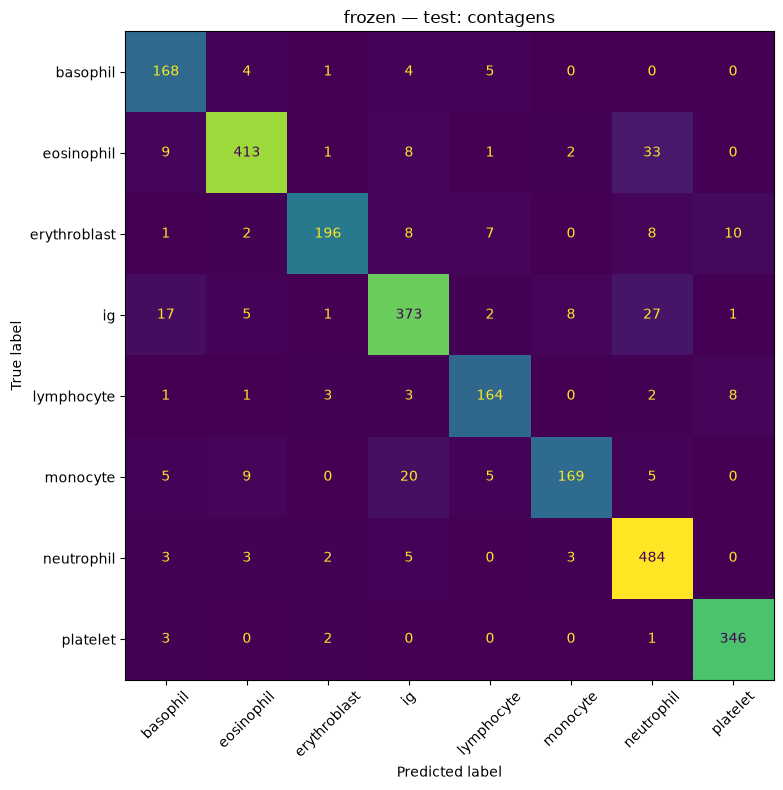

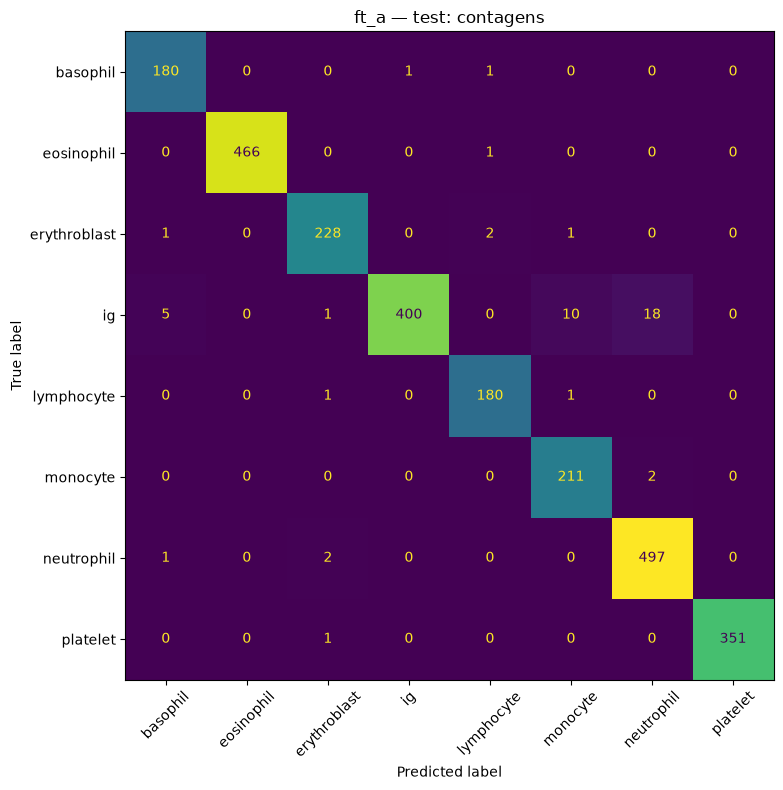

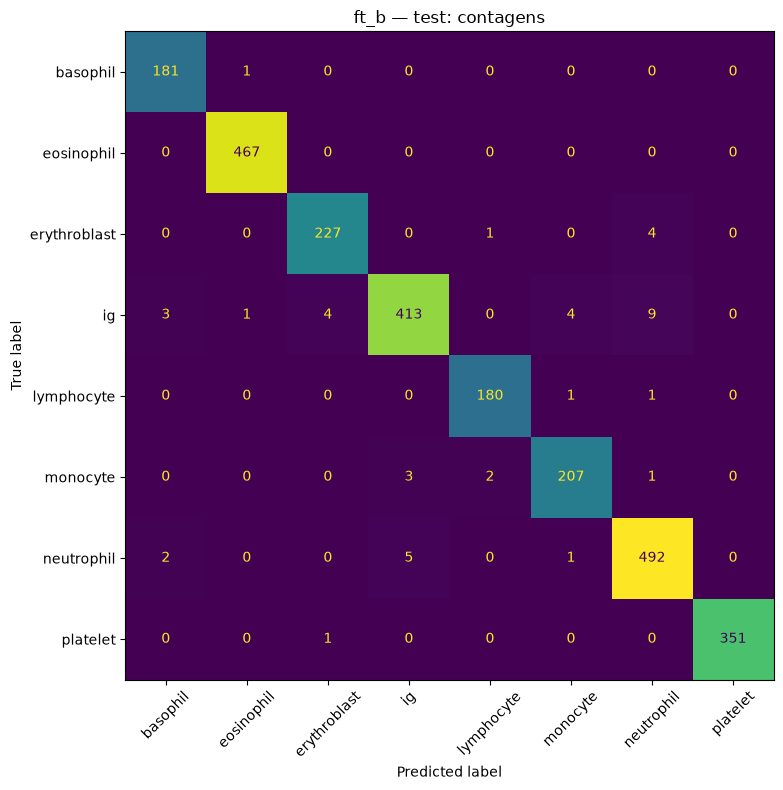

,model,loss,accuracy,balanced_accuracy,macro_f1,weighted_f1,trainable,epochs,seconds,time_measurement,time_note
0,frozen,0.288836,0.902810,0.894650,0.896897,0.902386,10248,15,5500.613553,measured,Tempo medido durante a execução.
1,ft_a,0.068947,0.980874,0.982758,0.980091,0.980776,3165988,12,5365.000000,estimate,Estimativa baseada no tempo acumulado impresso...
2,ft_b,0.049845,0.982826,0.983321,0.982495,0.982787,3952066,12,7991.018978,measured,Tempo medido durante a execução.


Recomendação anterior ao teste: ft_b


In [8]:
test_table, test_predictions = p.final_test(ROOT, parts, DEVICE)
display(test_table)
print('Recomendação anterior ao teste:', recommended)


### Discussão final após a avaliação no teste

#### Resultados e compatibilidade com a validação

A avaliação utilizou as mesmas **2.562 imagens de teste**, reservadas desde o início. O fine-tuning B já havia sido recomendado pelo maior macro F1 de validação e essa decisão foi mantida. O teste não orientou novos ajustes, treinamentos ou troca do modelo.

| Condição | Macro F1 na validação | Macro F1 no teste | Acurácia no teste | Balanced accuracy no teste | Acertos / erros no teste |
|---|---:|---:|---:|---:|---:|
| Base congelada | 89,31% | 89,69% | 90,28% | 89,47% | 2.313 / 249 |
| Fine-tuning A | 97,38% | 98,01% | 98,09% | 98,28% | 2.513 / 49 |
| Fine-tuning B | 98,19% | 98,25% | 98,28% | 98,33% | 2.518 / 44 |

O ranking observado na validação se manteve. O macro F1 de B no teste difere apenas **+0,06 ponto percentual** da validação; A apresenta +0,63 ponto e a base +0,38 ponto. Essas diferenças são compatíveis com variação entre as amostras dos dois holdouts, mas não comprovam generalização para outros pacientes, laboratórios ou microscópios.

O ganho de B sobre a base congelada foi de **8,56 pontos percentuais de macro F1**. Sobre A, o ganho foi menor: **0,24 ponto**, contra 0,81 ponto na validação. B teve cinco acertos líquidos adicionais, mas não acertou simplesmente todos os casos corretos de A: na comparação das mesmas imagens, corrigiu **27 erros de A** e introduziu **22 novos erros**. Logo, a vantagem global é pequena entre os fine-tunings e envolve trocas entre classes.

#### Classes e confusões mais relevantes

No modelo B, granulócitos imaturos mantiveram o menor F1 entre as oito classes (**96,61%**) e recall de **95,16%**: 21 das 434 imagens dessa classe foram atribuídas a outras classes. A confusão mais frequente foi granulócito imaturo → neutrófilo, com nove casos; o sentido inverso ocorreu cinco vezes. A semelhança morfológica é uma hipótese explicativa que exigiria revisão especializada, não uma conclusão obtida apenas pela matriz.

Os fine-tunings reduziram confusões expressivas da base. Por exemplo, eosinófilo → neutrófilo passou de 33 casos na base para zero em A e B. Granulócito imaturo → neutrófilo caiu de 27 casos na base para 18 em A e nove em B.

B não foi superior em todos os indicadores por classe. O recall de monócitos foi **97,18% em B**, contra **99,06% em A**; o recall de neutrófilos foi **98,40% em B**, contra **99,40% em A**. O F1 de eosinófilos e eritroblastos foi ligeiramente maior em A, e o de plaquetas empatou. Esses resultados impedem afirmar que B domina A em todas as situações. Em uma aplicação com prioridades diferentes por classe, seria necessário definir o custo dos erros previamente; neste estudo mantemos o critério de macro F1 estabelecido antes do teste.

#### Aprendizagem e explicabilidade

As curvas de B mostraram redução de loss e aproximação entre os F1 de treino e validação no final. O desempenho do teste não revelou uma queda agregada frente à validação. Assim, não há evidência forte de sobreajuste nessa divisão, embora isso não prove sua ausência. A oscilação de validação da A e o platô da base devem ser interpretados junto às métricas; a comparação de treino e validação também envolve augmentation e dropout somente no treino.

A análise de Grad-CAM foi realizada anteriormente com imagens de validação, sem selecionar mapas de teste para orientar a escolha. Nos exemplos corrigidos de linfócito e eritroblasto, os fine-tunings concentraram mais os destaques na célula de interesse. Nos granulócitos imaturos classificados incorretamente pelos fine-tunings, a célula também foi destacada. Portanto, localizar a célula não basta para distinguir seu tipo. Os mapas da classe real, com resolução original 7×7 e normalização individual, sustentam hipóteses qualitativas; não demonstram causalidade, precisão clínica ou superioridade de B em todos os casos.

#### Custo e condições de comparação

A base foi treinada por 15 épocas e seu melhor checkpoint de validação, da época 12, serviu como ponto de partida comum de A e B. A comparação utiliza as 12 épocas completas da A e as 12 realizadas pela B. Isso avalia o benefício de continuar o treinamento descongelando diferentes partes da rede; não isola o efeito de mais épocas do efeito de descongelar, pois não houve uma quarta condição com 12 épocas adicionais de base congelada. As estratégias A/B também variam simultaneamente blocos descongelados e learning rate, portanto comparamos estratégias completas.

O custo medido da etapa congelada foi **91,7 minutos**, comum às duas estratégias. A etapa B levou **133,2 minutos** e ajustou 3.952.066 parâmetros. A etapa A ajustou 3.165.988 parâmetros e tem tempo **estimado em 89,4 minutos**, recuperado do primeiro lote da época 13; não é uma medição exata das 12 épocas. A diferença aproximada de 43,8 minutos entre as etapas adicionais deve ser tratada com essa limitação, não como benchmark rigoroso. Os tempos representam treinamento com validações e salvamento dos melhores pesos, não latência de inferência.

Na validação, o maior macro F1 justificou a recomendação de B segundo o critério definido. O teste é compatível com essa expectativa, mas o ganho menor sobre A reforça que A é uma alternativa competitiva de menor custo de ajuste. Nenhuma preferência foi redefinida com base no teste.

#### Limitações e conclusão

O experimento utiliza uma única divisão estratificada e uma semente. Não foi realizada análise estatística para afirmar significância da pequena diferença entre A e B. A deduplicação de pixels evitou cópias exatas entre divisões, mas não elimina imagens semelhantes nem garante independência entre pacientes: não implementamos um holdout por paciente por ausência de identificação utilizada para esse fim. A validação foi usada repetidamente para selecionar checkpoints, e o teste confirma desempenho apenas dentro do protocolo e contexto de aquisição estudados.

As amostras são células normais provenientes de um contexto de aquisição específico. Mudanças de coloração, equipamento e população podem alterar o desempenho. O score softmax não foi calibrado e não deve ser interpretado como certeza clínica. O modelo classifica tipos celulares; o experimento não valida diagnóstico de doenças. A demonstração externa, registrada em Inferencia.ipynb, utilizou uma fotografia de neutrófilo de Tommaso Leonardi (Wikimedia Commons, domínio público). O modelo previu plaqueta com score de 86,45%, um erro que reforça a limitação frente a mudanças de enquadramento, escala e aquisição. Essas são hipóteses, não causas comprovadas. A demonstração não substitui o teste e não orientou novos ajustes.

Concluímos que o transfer learning com fine-tuning melhorou o desempenho em relação à base congelada neste conjunto. **Mantemos a recomendação prévia do fine-tuning B**, salvo como `models/selected.pt`, com macro F1 de teste de **98,25%**, reconhecendo a pequena vantagem sobre A, o maior custo e as limitações de generalização. Não foram realizados novos ajustes após consultar o teste.


## 11. Salvamento e reutilização
`models/selected.pt` contém state_dict, arquitetura, classes, tamanho e normalização. O notebook `Inferencia.ipynb` carrega esse checkpoint sem repetir o treinamento e permite avaliar uma imagem da internet com fonte e classe esperada. Execute-o e mantenha as saídas na entrega.

## Checklist final
- Preencher análises e declaração de IA com fatos verificados pela equipe.
- Salvar todas as saídas dos notebooks e preservar manifestos e ambiente.
- Executar inferência com imagem externa, registrando fonte, classe esperada, previsão e score.
- Montar os slides a partir de `slides/roteiro.md` com resultados reais, até 12 minutos.
- Entregar os notebooks, slides e modelo com informações de uso e link acessível.
- Todos devem compreender arquitetura, blocos, pré-processamento, estratégias e limitações.